# E-Commerce Share-to-Alpha — U.S. Warehousing and Logistics
**26 October 2026 · Reproduced retrospective macro pilot · NOT historical PIT or equity alpha.**

A falsifiable industry-demand study modeled on the K-Food v3 research structure. The notebook executes from frozen official-source CSV data and computes independent descriptive tables, walk-forward forecasts, sensitivity tests and figures. Every plot below is derived from the same checked-in observations.

## 01. Abstract
**Research question:** Does U.S. retail e-commerce share acceleration predict two-quarter-ahead warehousing employment YoY beyond warehouse persistence and national payroll growth? The primary scorecard covers 57 purged expanding-window origins. A better retrospective RMSE is not a causal or tradable alpha claim; the lack of historical release vintages is decisive.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
from run_analysis import ROOT, read_data, panel_for, walk_forward, metrics, block_bootstrap, block_placebo, run
raw=read_data();panel=panel_for(raw);oos=walk_forward(panel)
reported=json.loads((ROOT/'results/metrics.json').read_text())
assert len(raw)==107 and len(oos)==57
print('Data quarters:',len(raw),' | OOS origins:',len(oos),' | Date range:',raw.index.min().date(),'→',raw.index.max().date())

Data quarters: 107  | OOS origins: 57  | Date range: 2000-01-01 → 2026-07-01


In [2]:
display(pd.DataFrame(metrics(oos)).T.round(3))
print('Primary outcome: BLS NAICS 493 warehousing employment log YoY, two quarters ahead.')

,rmse,mae,n
mean,7.422,6.388,57.0
persistence,5.360,3.878,57.0
macro,5.869,4.147,57.0
full,5.172,3.616,57.0
ecom_only,7.111,4.643,57.0


Primary outcome: BLS NAICS 493 warehousing employment log YoY, two quarters ahead.


## 02. Research Design & Hypotheses
**H1:** increasing e-commerce share precedes greater storage/fulfillment employment. **H2:** a fixed factor adds predictive value beyond warehouse persistence and payroll. **H3:** gains withstand lag, horizon, segment and regime stress. **Null:** if simple baselines dominate or dependent-sample uncertainty includes zero, the candidate is not validated. **Counterthesis:** automation and outsourced/in-house fulfillment can break employment transmission.

In [3]:
print('Formation:',oos.index.min().date(),'to',oos.index.max().date())
print('Training origins at first test:',oos.training_n.iloc[0])
print('Targets overlap: quarterly observations forecast 2Q-ahead YoY. Do not use IID t-tests.')

Formation: 2012-01-01 to 2026-01-01
Training origins at first test: 41
Targets overlap: quarterly observations forecast 2Q-ahead YoY. Do not use IID t-tests.


## 03. Industry Context
U.S. Census retail e-commerce share rose to 17.1% in 2026Q2 from 16.3% in 2025Q2 (Census report published 18 August 2026). The employment proxy is BLS Current Employment Statistics, not fulfillment throughput or revenue. Structural online-channel growth and warehouse hiring are related but need not be proportional.

In [4]:
display(raw[['ECOMPCTSA','CES4349300001','CES4349200001']].tail(9).round(2))
print('E-commerce share latest:',raw.ECOMPCTSA.dropna().iloc[-1],'%')

,ECOMPCTSA,CES4349300001,CES4349200001
observation_date,,,
2024-07-01,16.2,1870.9,1090.5
2024-10-01,16.2,1877.3,1091.9
2025-01-01,16.0,1881.8,1104.5
2025-04-01,16.3,1876.2,1080.0
2025-07-01,16.4,1864.0,1091.8
2025-10-01,16.7,1839.4,1063.8
2026-01-01,17.0,1831.3,1058.9
2026-04-01,17.1,1841.6,1091.2
2026-07-01,NaN,1835.4,1091.3


E-commerce share latest: 17.1 %


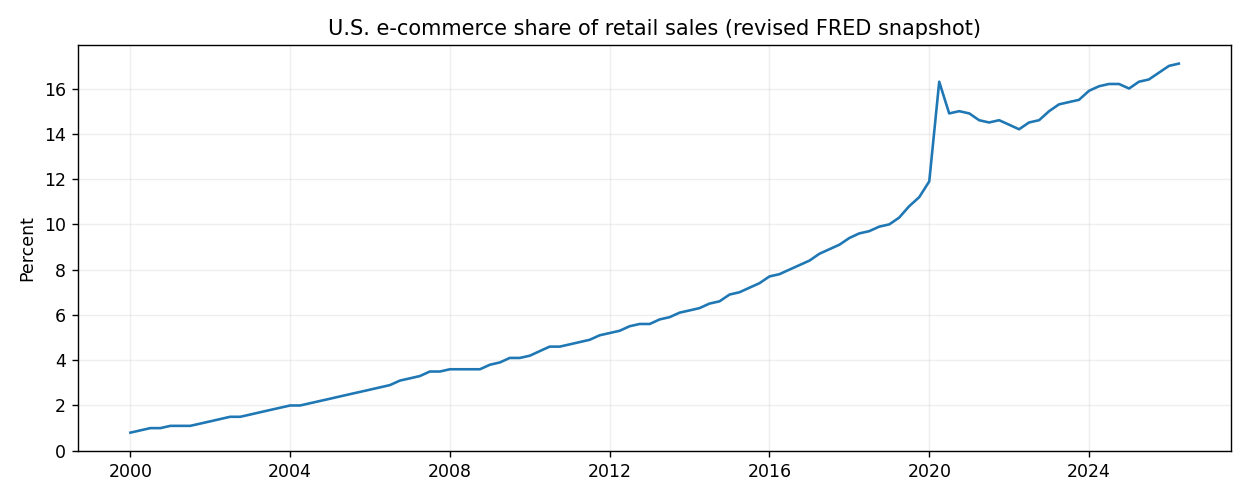

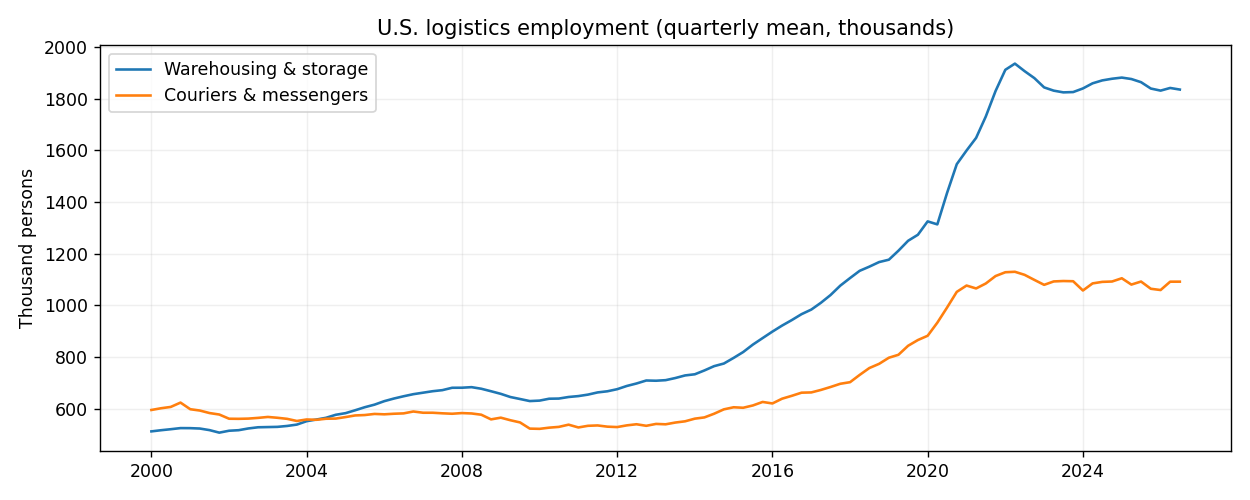

In [5]:
display(Image(filename=str(ROOT/'figures/01_ecommerce_share.png')))
display(Image(filename=str(ROOT/'figures/02_logistics_employment.png')))

## 04. Data & Source Integrity
**Source A:** U.S. Census Bureau (`ECOMPCTSA`) and BLS CES (`CES4349300001`, `CES4349200001`, `PAYEMS`) via FRED. Warehouse/courier/payroll monthly SA counts are converted to arithmetic quarterly means using FRED graph options; no synthetic observations. All 107 quarterly rows are frozen and source URLs/units/last known releases are recorded below. The source CSV is latest revised, not an ALFRED vintage panel.

In [6]:
sources=pd.read_csv(ROOT/'data/source_register.csv')
display(sources[['series_id','publisher','units','observations','source_release_latest_known','historical_vintages','quality']])

,series_id,publisher,units,observations,source_release_latest_known,historical_vintages,quality
0,ECOMPCTSA,U.S. Census Bureau via FRED,percent of retail sales SA,2000Q1-2026Q2,2026-08-18,NOT RETRIEVED,A
1,CES4349300001,U.S. Bureau of Labor Statistics via FRED,thousands persons SA,2000Q1-2026Q3,2026-10-02,NOT RETRIEVED,A
2,CES4349200001,U.S. Bureau of Labor Statistics via FRED,thousands persons SA,2000Q1-2026Q3,2026-10-02,NOT RETRIEVED,A
3,PAYEMS,U.S. Bureau of Labor Statistics via FRED,thousands persons SA,2000Q1-2026Q3,2026-10-02,NOT RETRIEVED,A


In [7]:
print('Missing observations per series:')
display(raw.isna().sum().to_frame('missing'))
assert raw.index.is_monotonic_increasing and raw.index.is_unique
assert raw.loc['2026-04-01','ECOMPCTSA']==17.1
print('Frozen CSV SHA-256:',hashlib.sha256((ROOT/'data/fred_quarterly_snapshot_2026-10-26.csv').read_bytes()).hexdigest())

Missing observations per series:


,missing
ECOMPCTSA,1
CES4349300001,0
CES4349200001,0
PAYEMS,0


Frozen CSV SHA-256: 17b99d105505b7c4ef7741012cf65d916bac0b907403474f18cffedcc4a99b2d


## 05. Point-in-Time Availability
At **end-of-quarter t**, features are based on quarter **t−1** or earlier, giving one full-quarter publication buffer. An origin `u` enters the training set at `t` only if `u+2+1 <= t`, reflecting two-quarter target maturity plus a one-quarter reporting buffer. **This is not genuine PIT** because original Census and BLS historical vintages were not downloaded; even old observations may have been revised years later.

In [8]:
sample=oos.iloc[0]
print('First forecast origin:',oos.index[0].date(),' | matured training observations:',sample.training_n)
print('Last forecast origin:',oos.index[-1].date(),' | matured training observations:',oos.training_n.iloc[-1])
assert (panel.origin_number<=sample.origin_number-3).sum()==sample.training_n

First forecast origin: 2012-01-01  | matured training observations: 41.0
Last forecast origin: 2026-01-01  | matured training observations: 97


In [9]:
display(panel[['origin_number','ecom_delta','ecom_factor','known_yoy','payroll_yoy','target']].head(8).round(3))
print('The panel is an analysis snapshot; it does not assert observation-level release dates.')

,origin_number,ecom_delta,ecom_factor,known_yoy,payroll_yoy,target
observation_date,,,,,,
2001-04-01,5,0.3,0.149,2.415,1.138,-3.416
2001-07-01,6,0.2,0.100,1.252,0.281,-1.927
2001-10-01,7,0.1,0.050,-0.676,-0.213,-1.233
2002-01-01,8,0.2,0.100,-3.416,-1.022,1.232
2002-04-01,9,0.2,0.100,-1.927,-1.498,4.025
2002-07-01,10,0.3,0.149,-1.233,-1.329,2.726
2002-10-01,11,0.4,0.197,1.232,-1.089,2.469
2003-01-01,12,0.3,0.149,4.025,-0.479,1.839


The panel is an analysis snapshot; it does not assert observation-level release dates.


## 06. Factor Construction
Let `E` be online retail share in percentage points, `W` warehouse employment, `P` total nonfarm payroll. **Pre-fixed signal:** `F_t=tanh((E_{t−1}−E_{t−5})/2)`. **Known controls:** `100 ln(W_{t−1}/W_{t−5})` and `100 ln(P_{t−1}/P_{t−5})`. **Target:** `100 ln(W_{t+2}/W_{t−2})`. Ridge penalty 10 is fixed; all standardization is fit on the training window only. No optimized factor thresholds or whole-sample z-scores.

In [10]:
display(panel[['ecom_delta','ecom_factor','known_yoy','payroll_yoy','target']].describe().round(3))
print('Factor finite:',np.isfinite(panel.ecom_factor).all(),'bounded:',panel.ecom_factor.abs().max()<=1)

,ecom_delta,ecom_factor,known_yoy,payroll_yoy,target
count,100.000,100.000,100.000,100.000,100.000
mean,0.617,0.253,5.126,0.730,5.035
std,0.873,0.230,5.918,2.569,6.002
min,-1.700,-0.691,-6.062,-11.948,-6.062
25%,0.300,0.149,1.925,0.261,1.764
50%,0.500,0.245,4.549,1.440,4.549
75%,0.725,0.347,8.444,1.745,8.444
max,6.000,0.995,22.728,8.213,22.728


Factor finite: True bounded: True


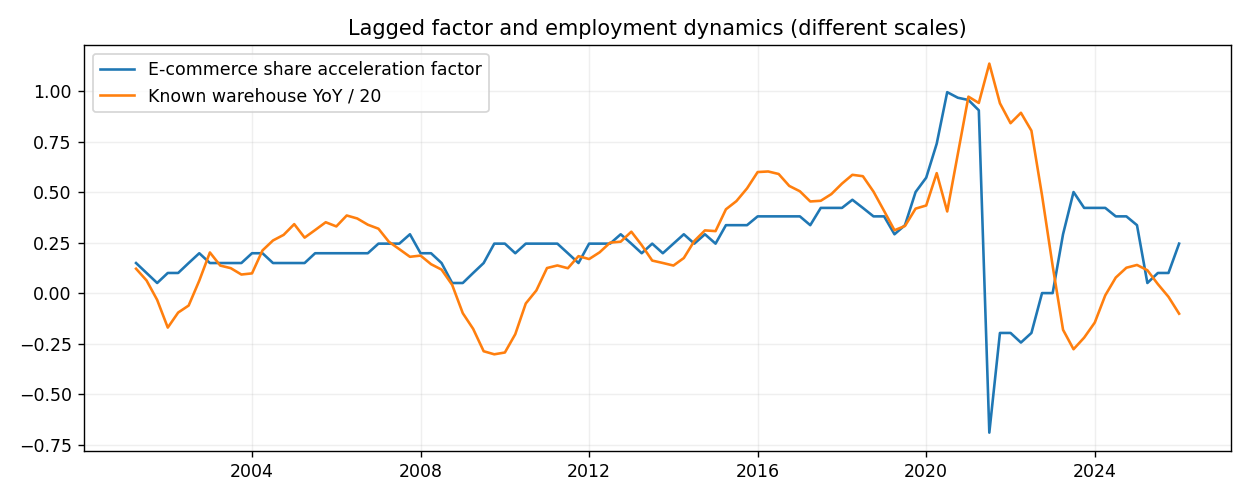

In [11]:
display(Image(filename=str(ROOT/'figures/03_factor_dynamics.png')))

## 07. Exposure & Transmission
The primary outcome represents NAICS 493 warehouse employment, not a publicly traded security. A 50–100% warehouse and 0–50% courier segment mix is a **scenario** for industry-definition uncertainty; it does not represent observed historical company product/revenue weights. Dated firm-level exposure mapping is **unavailable**; firm earnings, IC, excess equity returns and transaction-cost metrics are **NOT TESTED**.

In [12]:
exposure=pd.read_csv(ROOT/'data/exposure_map.csv')
display(exposure)
print('Exposure perturbation is an outcome-composition stress test, not a company portfolio backtest.')

,segment,NAICS,primary_outcome_weight,scenario_weight_range,dated_historical_company_exposure,description
0,Warehousing and storage,493,1.0,0.5-1.0,NOT AVAILABLE,Direct demand transmission via storage and ful...
1,Couriers and messengers,492,0.0,0.0-0.5,NOT AVAILABLE,Related delivery segment used as outcome sensi...


Exposure perturbation is an outcome-composition stress test, not a company portfolio backtest.


## 08. Outcomes & Baselines
Five expanding-window competitors are scored on **identical origins**: historical mean; warehouse persistence; warehouse persistence + payroll; both controls + e-commerce share; e-commerce alone. The earliest 2012Q1 origin has at least 41 matured training observations. Targets and training windows are purged to avoid obvious label look-ahead; revised historical observations remain a separate unresolved issue.

In [13]:
scores=pd.DataFrame(metrics(oos)).T.round(4)
display(scores)
assert scores.n.nunique()==1
print('Full vs macro RMSE gain (pp):',round(scores.loc['macro','rmse']-scores.loc['full','rmse'],4))

,rmse,mae,n
mean,7.4225,6.3876,57.0
persistence,5.3603,3.8776,57.0
macro,5.8685,4.1467,57.0
full,5.1722,3.6161,57.0
ecom_only,7.1111,4.6430,57.0


Full vs macro RMSE gain (pp): 0.6963


In [14]:
display(oos[['actual','mean','persistence','macro','full','training_n']].head(8).round(3))
display(oos[['actual','macro','full']].tail(8).round(3))

,actual,mean,persistence,macro,full,training_n
origin,,,,,,
2012-01-01,5.092,2.260,2.898,3.399,4.491,41
2012-04-01,6.081,2.303,3.277,3.828,4.881,42
2012-07-01,4.746,2.365,3.822,4.123,5.146,43
2012-10-01,3.221,2.427,3.935,4.214,5.988,44
2013-01-01,2.983,2.509,4.536,4.609,5.547,45
2013-04-01,2.729,2.557,3.862,4.117,4.249,46
2013-07-01,3.472,2.571,3.037,3.626,4.472,47
2013-10-01,5.162,2.580,2.875,3.550,3.638,48


,actual,macro,full
origin,,,
2024-04-01,2.787,0.949,3.621
2024-07-01,2.263,2.411,4.322
2024-10-01,0.889,3.304,4.939
2025-01-01,-0.369,3.576,4.664
2025-04-01,-2.040,3.325,1.566
2025-07-01,-2.720,2.414,1.181
2025-10-01,-1.861,1.544,0.361
2026-01-01,-1.546,0.436,0.650


## 09. Empirical Findings
In 57 forecasts, the augmented model RMSE is **5.172 pp** versus **5.869 pp** for macro controls, **5.360 pp** for persistence and **7.422 pp** for historical mean. The e-commerce-only model is substantially weaker. The macro gain is positive in this frozen retrospective exercise, but effect stability, release-vintage leakage and statistical dependence prevent an alpha conclusion.

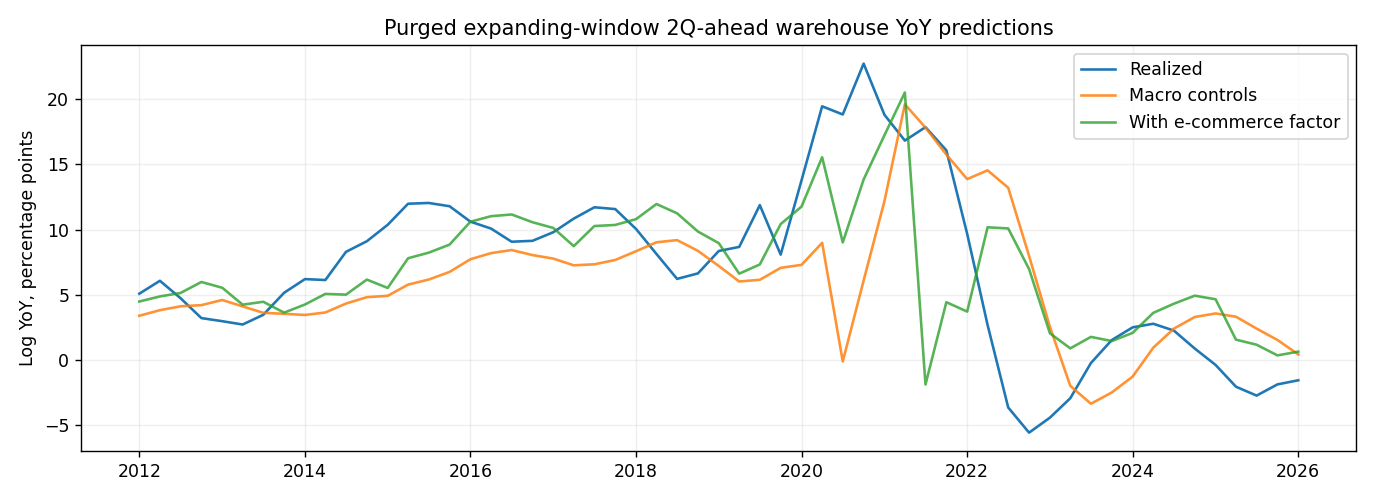

In [15]:
display(Image(filename=str(ROOT/'figures/04_oos_forecasts.png')))

Average paired squared loss improvement: 7.6885 squared pp
Positive loss improvement origins: 38 / 57


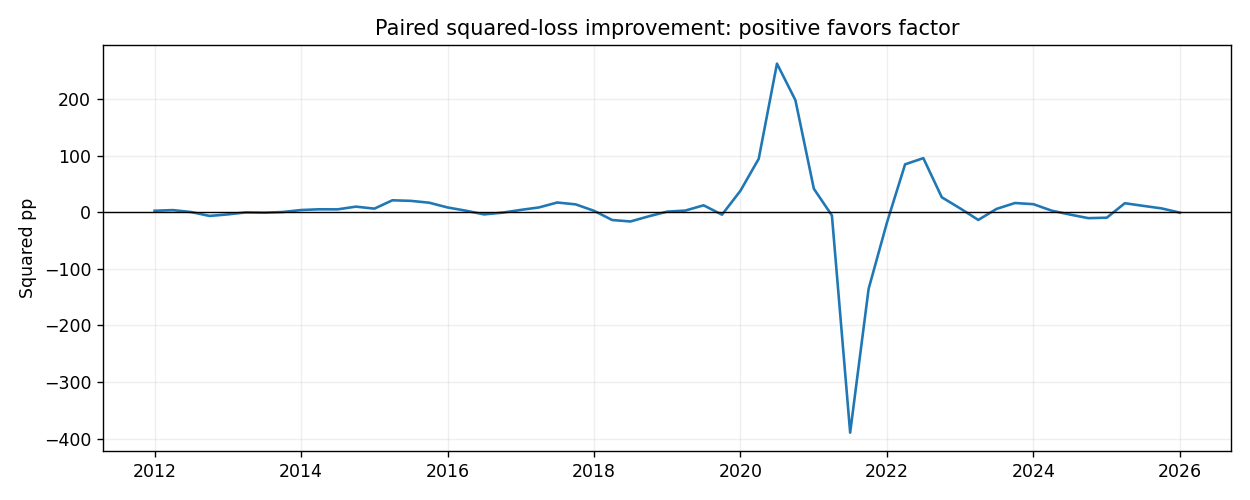

In [16]:
oos['loss_improvement']=(oos.macro-oos.actual)**2-(oos.full-oos.actual)**2
print('Average paired squared loss improvement:',round(oos.loss_improvement.mean(),4),'squared pp')
print('Positive loss improvement origins:',int((oos.loss_improvement>0).sum()),'/',len(oos))
display(Image(filename=str(ROOT/'figures/05_loss_difference.png')))

## 10. Robustness & Placebos
The **1,000-refit 4-quarter block-shuffle** preserves within-block structure but does not justify an exact permutation p-value under trend/nonstationarity. The **2,000-draw 4-quarter moving-block bootstrap** resamples paired OOS errors, not individual observations. Segment-mix perturbations (1,000 draws) and horizon/lag ablations test whether the association depends on a particular specification.

In [17]:
placebo=reported['placebo'];boot=reported['uncertainty'];sens=reported['exposure_sensitivity']
display(pd.DataFrame({'measure':['observed delta RMSE','block-shuffle exploratory tail','bootstrap CI lower','bootstrap CI upper','segment-mix median'],
'value':[placebo['observed_delta_rmse'],placebo['exploratory_right_tail_fraction'],*boot['delta_rmse_macro_minus_full_ci95'],sens['delta_rmse_median']]}).round(4))

,measure,value
0,observed delta RMSE,0.6964
1,block-shuffle exploratory tail,0.0010
2,bootstrap CI lower,-1.4857
3,bootstrap CI upper,2.5724
4,segment-mix median,0.6743


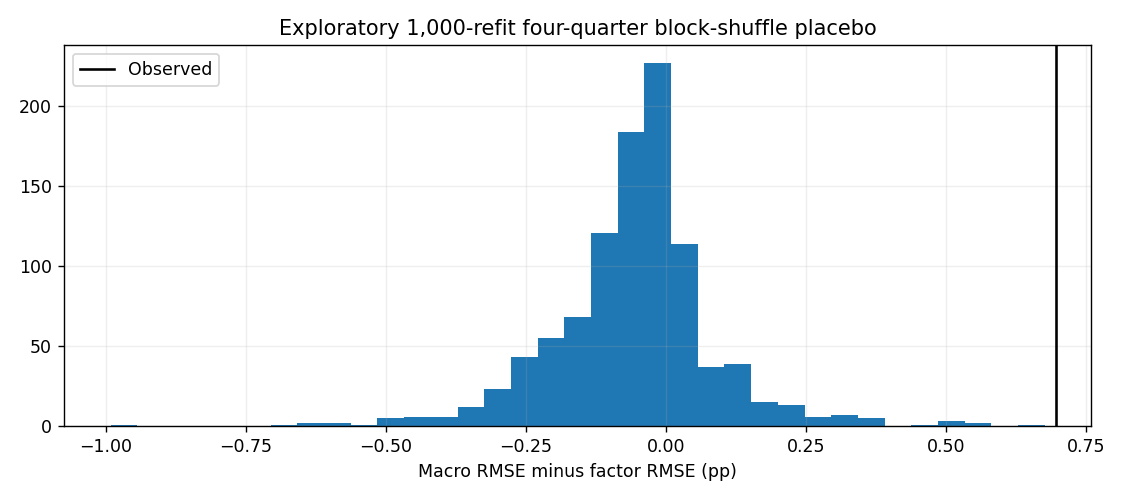

Caution: the small exploratory block-shuffle tail fraction is NOT an exact significance level.


In [18]:
display(Image(filename=str(ROOT/'figures/06_block_placebo.png')))
print('Caution: the small exploratory block-shuffle tail fraction is NOT an exact significance level.')

In [19]:
rob=pd.DataFrame(reported['robustness']).T
rob['delta_rmse_macro_minus_full']=rob.macro_rmse-rob.full_rmse
display(rob.round(3))

,n,macro_rmse,full_rmse,delta_rmse_macro_minus_full
horizon_1q,58.0,4.553,4.053,0.500
horizon_4q,55.0,7.347,5.435,1.912
lag_2q,57.0,5.979,5.300,0.679
lag_3q,57.0,6.015,5.436,0.580
pre_covid,32.0,3.136,2.544,0.592
covid_and_after,25.0,8.120,7.260,0.860
exclude_2020_2021,49.0,4.792,4.014,0.777
courier_negative_control,57.0,5.303,4.757,0.546


## 11. Regime Sensitivity
Pre-2020 and 2020+ origins are scored separately without refitting models by regime. The candidate improves on the macro model in both subsamples, but 2020+ errors are much larger. A courier outcome check is **not a valid unaffected negative control**: delivery hiring may respond to online sales as well, so similar results imply non-specificity, not external validation.

In [20]:
display(rob.loc[['pre_covid','covid_and_after','exclude_2020_2021','courier_negative_control'],['n','macro_rmse','full_rmse','delta_rmse_macro_minus_full']].round(3))

,n,macro_rmse,full_rmse,delta_rmse_macro_minus_full
pre_covid,32.0,3.136,2.544,0.592
covid_and_after,25.0,8.120,7.260,0.860
exclude_2020_2021,49.0,4.792,4.014,0.777
courier_negative_control,57.0,5.303,4.757,0.546


In [21]:
for tag,mask in [('pre-2020',oos.index<'2020-01-01'),('2020+',oos.index>='2020-01-01')]:
 z=oos.loc[mask];print(tag, 'n=',len(z),'mean actual=',round(z.actual.mean(),3),'RMSE factor=',round(metrics(z)['full']['rmse'],3))

pre-2020 n= 32 mean actual= 8.137 RMSE factor= 2.544
2020+ n= 25 mean actual= 5.657 RMSE factor= 7.26


## 12. Bias Audit & Verdict
**Unresolved vintage/revision leakage** is the most consequential weakness. A conservative t−1 buffer does not recover the historical data actually visible at each formation date. Additional limitations: nonstationarity and COVID structural break, multiple exploratory variants, overlapping targets, national-level selection, no independent firm sample, no delisting-adjusted total returns, no trading costs, and invalid exact-exchangeability assumptions for the block shuffle. **Verdict:** promising *retrospective macro lead-factor candidate*, not verified PIT and not equity alpha.

In [22]:
for i,w in enumerate(reported['warnings'],1):print(f'{i}. {w}')
assert boot['delta_rmse_macro_minus_full_ci95'][0]<0<boot['delta_rmse_macro_minus_full_ci95'][1]
print('Inference gate: bootstrap interval includes zero; no reliable positive alpha claim.')

1. No ALFRED/Census/BLS historical vintages: one-quarter lag is conservative assumption, not PIT proof.
2. Macro employment is not firm fundamentals or adjusted security returns.
3. Overlapping two-quarter forecast targets induce dependent errors.
4. Block-shuffle null is exploratory, not an exact permutation test.
5. Data collection snapshot contains 2026 Q3 employment but e-commerce only through Q2.
Inference gate: bootstrap interval includes zero; no reliable positive alpha claim.


## 13. Reproduction
From a clean checkout, install `requirements.txt`, run `python run_analysis.py`, `pytest -q tests`, and execute this notebook with `jupyter nbconvert --to notebook --execute research.ipynb`. From repository root run `python scripts/validate_studies.py`. Frozen raw inputs, derived panel, all OOS forecasts, uncertainty tables and six calculated diagnostic figures are committed; no network request is needed for reproduction.

In [23]:
print('Saved artifact checks:')
for p in [ROOT/'data/derived_factor_panel.csv',ROOT/'results/walk_forward_oos.csv',ROOT/'results/metrics.json',ROOT/'figures/06_block_placebo.png']:
 print(p.relative_to(ROOT),p.exists(),p.stat().st_size if p.exists() else None)
assert all(p.exists() for p in (ROOT/'figures').glob('*.png'))

Saved artifact checks:
data/derived_factor_panel.csv True 8853
results/walk_forward_oos.csv True 5243
results/metrics.json True 3302
figures/06_block_placebo.png True 30629


In [24]:
from run_analysis import ridge_fit_predict
z=np.array([[1.],[2.],[3.],[4.]])
assert np.isfinite(ridge_fit_predict(z,np.array([1.,2.,3.,4.]),np.array([2.5])))
print('Closed-form train-only ridge smoke test passed.')

Closed-form train-only ridge smoke test passed.


## 14. Next-Stage Protocol
Obtain archived quarter-specific Census releases and BLS vintage files, rebuild the panel using actual release timestamps, and rerun with a locked 2022–2027 holdout. Add independently dated warehouse capacity, automation capex, shipment volumes and company segment financials; only then examine historical-universe adjusted total returns with costs and multiple-testing controls. Prefer a genuinely prospective test over tuning the same retrospective sample.

In [25]:
print('Next gate: source-vintage verification -> independent firm fundamentals -> security total returns -> costs.')
print('No historical PIT evidence or company-level investable alpha is present in this study.')

Next gate: source-vintage verification -> independent firm fundamentals -> security total returns -> costs.
No historical PIT evidence or company-level investable alpha is present in this study.


## 15. Sources & Artifacts
Primary publishers: U.S. Census Bureau and U.S. Bureau of Labor Statistics, via the Federal Reserve Bank of St. Louis. Official series: [ECOMPCTSA](https://fred.stlouisfed.org/series/ECOMPCTSA), [CES4349300001](https://fred.stlouisfed.org/series/CES4349300001), [CES4349200001](https://fred.stlouisfed.org/series/CES4349200001), [PAYEMS](https://fred.stlouisfed.org/series/PAYEMS). Latest e-commerce release: 2026-08-18; latest BLS CES release: 2026-10-02. **Historical observation release timestamps: UNKNOWN.** See `data/source_register.csv`, `data/fred_quarterly_snapshot_2026-10-26.csv`, `results/`, `figures/`, `tests/` and `README.md`.

In [26]:
print('Official source URLs:')
for u in sources.source_url:print(' •',u)
print('End of research notebook. Evidence level: reproduced retrospective macro pilot.')

Official source URLs:
 • https://fred.stlouisfed.org/series/ECOMPCTSA
 • https://fred.stlouisfed.org/series/CES4349300001
 • https://fred.stlouisfed.org/series/CES4349200001
 • https://fred.stlouisfed.org/series/PAYEMS
End of research notebook. Evidence level: reproduced retrospective macro pilot.
